# **Glass Type Classification with Machine Learning**

## Introduction

Glass identification is an important classification problem, particularly in forensic investigations, where glass fragments can provide useful evidence.

In this project, we analyse the **Glass Identification Dataset** from the UCI Machine Learning Repository. The dataset contains **214 samples, 9 numerical features and 6 glass types**.

The objective is to predict the type of glass based on its **refractive index and chemical composition**.

We perform **Exploratory Data Analysis (EDA)** to understand the dataset and compare two machine learning classification algorithms: **Gaussian Naive Bayes** and **Decision Tree Classifier**.

Finally, we evaluate the models using **Accuracy, Precision, Recall, F1-Score and Confusion Matrix** to determine which model performs better.

## Data Dictionary

The dataset contains **214 samples, 9 numerical features and 1 target variable**.

| Column Name | Description |
|---|---|
| RI | Refractive index of the glass |
| Na | Sodium content (weight percent in corresponding oxide) |
| Mg | Magnesium content (weight percent in corresponding oxide) |
| Al | Aluminum content (weight percent in corresponding oxide) |
| Si | Silicon content (weight percent in corresponding oxide) |
| K | Potassium content (weight percent in corresponding oxide) |
| Ca | Calcium content (weight percent in corresponding oxide) |
| Ba | Barium content (weight percent in corresponding oxide) |
| Fe | Iron content (weight percent in corresponding oxide) |
| Type | Target variable representing the glass category (6 classes present in the dataset) |

**Target Variable:** `Type`

**Features (X):** RI, Na, Mg, Al, Si, K, Ca, Ba, Fe

**Missing Values:** None

<img src="images/glass_cover.png" width="700">

#### Dataset Source

**Dataset:** [Glass Identification – UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/42/glass+identification)

**Author:** B. German (1987)

## Import Libraries

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt

## Data Loading

In [2]:
df = pd.read_csv('glass.csv')

## Exploratory Data Analysis (EDA)

In [3]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [4]:
df.shape

(214, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [6]:
df.columns

Index(['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'], dtype='str')

In [7]:
df.isnull().sum()

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

In [8]:
df['Type'].value_counts()

Type
2    76
1    70
7    29
3    17
5    13
6     9
Name: count, dtype: int64

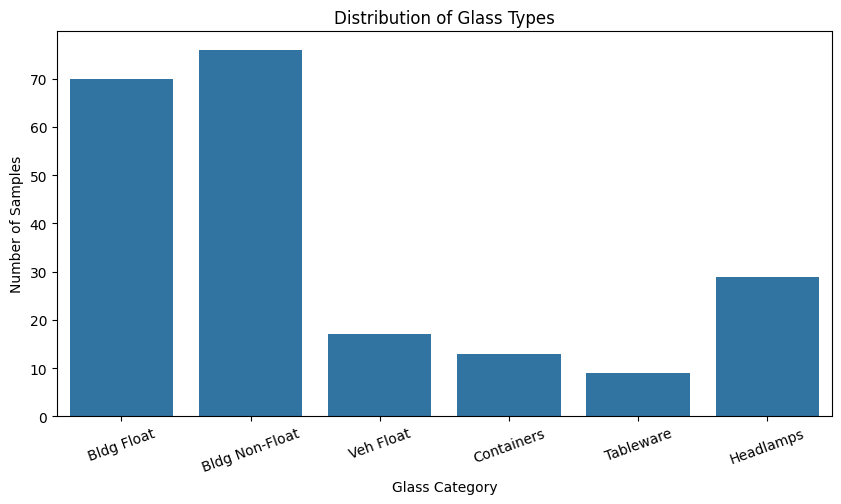

In [9]:
plt.figure(figsize=(10, 5))

order = [1, 2, 3, 5, 6, 7]
labels = ['Bldg Float', 'Bldg Non-Float', 'Veh Float', 'Containers', 'Tableware', 'Headlamps']

ax = sns.countplot(data=df, x='Type', order=order)

ax.set_title('Distribution of Glass Types')
ax.set_xlabel('Glass Category')
ax.set_ylabel('Number of Samples')
plt.xticks(ticks=range(6), labels=labels, rotation=20)

plt.show()

>**Observation:** The dataset is imbalanced, as Glass Types 1 and 2 contain noticeably more samples than the other classes

In [10]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [11]:
df.corr(numeric_only=True)

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
RI,1.000000,-0.191885,-0.122274,-0.407326,-0.542052,-0.289833,0.810403,-0.000386,0.143010,-0.164237
Na,-0.191885,1.000000,-0.273732,0.156794,-0.069809,-0.266087,-0.275442,0.326603,-0.241346,0.502898
Mg,-0.122274,-0.273732,1.000000,-0.481799,-0.165927,0.005396,-0.443750,-0.492262,0.083060,-0.744993
Al,-0.407326,0.156794,-0.481799,1.000000,-0.005524,0.325958,-0.259592,0.479404,-0.074402,0.598829
Si,-0.542052,-0.069809,-0.165927,-0.005524,1.000000,-0.193331,-0.208732,-0.102151,-0.094201,0.151565
K,-0.289833,-0.266087,0.005396,0.325958,-0.193331,1.000000,-0.317836,-0.042618,-0.007719,-0.010054
Ca,0.810403,-0.275442,-0.443750,-0.259592,-0.208732,-0.317836,1.000000,-0.112841,0.124968,0.000952
Ba,-0.000386,0.326603,-0.492262,0.479404,-0.102151,-0.042618,-0.112841,1.000000,-0.058692,0.575161
Fe,0.143010,-0.241346,0.083060,-0.074402,-0.094201,-0.007719,0.124968,-0.058692,1.000000,-0.188278
Type,-0.164237,0.502898,-0.744993,0.598829,0.151565,-0.010054,0.000952,0.575161,-0.188278,1.000000


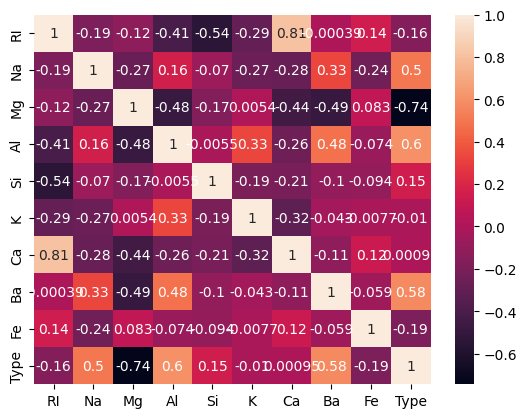

In [12]:
sns.heatmap(df.corr(numeric_only=True),annot=True);

## Feature Selection (x and y)

In [13]:
x = df.drop('Type', axis=1)
y = df['Type']

## Modelling

### Gaussian Naive Bayes

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)

In [16]:
from sklearn.naive_bayes import GaussianNB

In [17]:
g=GaussianNB()

In [18]:
g.fit(x_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](6,)","[59.,62.,14., 9., 6.,21.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](6,)","[0.35,0.36,0.08,0.05,0.04,0.12]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](6,)","[1,2,3,5,6,7]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.996e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['RI','Na','Mg',...,'Ca','Ba','Fe']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](6, 9)","[[ 1.52,13.27, 3.56,..., 8.77, 0.02, 0.06], [ 1.52,13.14, 2.99,..., 9.11, 0.06, 0.09], [ 1.52,13.43, 3.54,..., 8.8 , 0.01, 0.06], [ 1.52,12.74, 1.08,..., 9.96, 0.27, 0.06], [ 1.52,14.31, 1.58,..., 9.57, 0. , 0. ], [ 1.52,14.42, 0.66,..., 8.41, 1.07, 0.01]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](6, 9)","[[0. ,0.25,0.06,...,0.33,0.01,0.01], [0. ,0.4 ,1.6 ,...,3.66,0.16,0.01], [0. ,0.29,0.03,...,0.15,0. ,0.01], [0. ,0.75,1.02,...,4.36,0.47,0.03], [0. ,0.16,0.81,...,1.15,0. ,0. ], [0. ,0.56,1.48,...,1.2 ,0.52,0. ]]"


In [19]:
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report

In [20]:
gtahmin=g.predict(x_test)

In [21]:
accuracy_score(y_test, gtahmin)

0.5581395348837209

In [22]:
confusion_matrix(y_test, gtahmin)

array([[7, 1, 3, 0, 0, 0],
       [9, 3, 0, 1, 0, 1],
       [1, 0, 2, 0, 0, 0],
       [0, 3, 0, 1, 0, 0],
       [0, 0, 0, 0, 3, 0],
       [0, 0, 0, 0, 0, 8]])

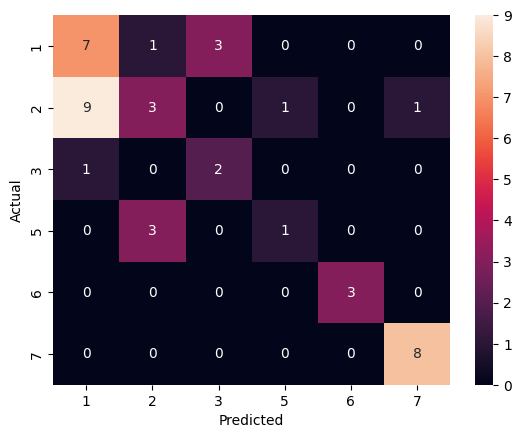

In [23]:
labels = [1, 2, 3, 5, 6, 7]

sns.heatmap(
    confusion_matrix(y_test, gtahmin, labels=labels),
    annot=True,
    fmt='d',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [24]:
print(classification_report(y_test, gtahmin))

              precision    recall  f1-score   support

           1       0.41      0.64      0.50        11
           2       0.43      0.21      0.29        14
           3       0.40      0.67      0.50         3
           5       0.50      0.25      0.33         4
           6       1.00      1.00      1.00         3
           7       0.89      1.00      0.94         8

    accuracy                           0.56        43
   macro avg       0.60      0.63      0.59        43
weighted avg       0.55      0.56      0.53        43



### Decision Tree Classifier

In [25]:
from sklearn.tree import DecisionTreeClassifier

In [26]:
d = DecisionTreeClassifier(random_state=42)

In [27]:
d.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [28]:
dtahmin=d.predict(x_test)

In [29]:
accuracy = accuracy_score(y_test, dtahmin)

In [30]:
print("Accuracy:", accuracy)

Accuracy: 0.7209302325581395


In [31]:
print(classification_report(y_test, dtahmin))

              precision    recall  f1-score   support

           1       0.71      0.91      0.80        11
           2       0.64      0.50      0.56        14
           3       0.60      1.00      0.75         3
           5       0.50      0.25      0.33         4
           6       1.00      0.67      0.80         3
           7       0.89      1.00      0.94         8

    accuracy                           0.72        43
   macro avg       0.72      0.72      0.70        43
weighted avg       0.71      0.72      0.70        43



In [32]:
confusion_matrix(y_test, dtahmin)

array([[10,  0,  0,  1,  0,  0],
       [ 4,  7,  2,  0,  0,  1],
       [ 0,  0,  3,  0,  0,  0],
       [ 0,  3,  0,  1,  0,  0],
       [ 0,  1,  0,  0,  2,  0],
       [ 0,  0,  0,  0,  0,  8]])

## Conclusion

In this project, the **Glass Identification Dataset** was analysed to classify different types of glass based on their refractive index and chemical composition.

The dataset contains **214 samples, 9 numerical features and 6 glass classes**. No missing values were found. Exploratory Data Analysis showed that the dataset is imbalanced, with Glass Types 1 and 2 containing the largest number of samples.

Two classification algorithms were compared:

- **Gaussian Naive Bayes:** 55.81% Accuracy
- **Decision Tree Classifier:** 72.09% Accuracy

The Decision Tree also achieved a **weighted F1-score of approximately 0.70**, outperforming Gaussian Naive Bayes on the test set.

Overall, this project demonstrates a complete basic classification workflow, including **data exploration, feature selection, model training, prediction and evaluation**.

As the dataset is relatively small and the results are based on a single train-test split, future improvements could include **cross-validation, hyperparameter tuning and additional classification algorithms**.